# Task 2: Random Forest Classifier
### Customer Segmentation — DA Assignment 4, Section 1

Scratch random forest: own bootstrap sampling of rows, own aggregation (majority vote) and own OOB estimate.
The individual trees are `sklearn.tree.DecisionTreeClassifier` with `max_features="sqrt"`, i.e. a **fresh random
feature subset is drawn at every split** (the tree gets all features and sub-samples them per node).
No `RandomForestClassifier`, `ExtraTreesClassifier` or `BaggingClassifier` is used.

**What is implemented by us vs. by the base learner (Task 2a).**

| Forest component | Where it happens |
|---|---|
| Bootstrap sampling of rows | **Our code**: `rng.randint(0, n, size=n)` draws n rows with replacement for every tree |
| Random feature sub-sampling at **every split** | Inside each tree: we build every tree with `max_features="sqrt"`, so at **each node** the tree draws a new random subset of √p features and searches for the best split only among them. Each tree gets its own seed from our RNG, so the subsets are different at every node and in every tree. This is the per-split sampling of Breiman (2001); it is *not* a single feature subset per tree. |
| Aggregation of tree predictions | **Our code**: majority vote over the trees, with an explicit tie rule (larger training prior, then a seeded random choice) |
| Out-of-bag predictions and OOB accuracy | **Our code**: rows not drawn into a tree's bootstrap sample are predicted by that tree, and the same vote is applied |

The assignment explicitly allows sklearn for the decision trees in Task 2. Per-split feature sampling has to happen inside the tree's split search, because that is the only place where a new subset can be drawn at every node. So we use the tree's `max_features` option for it. The forest itself (bootstrap, randomisation seeds, voting, OOB) is entirely our own code.

Preprocessing (median / most-frequent imputation, ordinal `Spending_Score` Low < Average < High, one-hot nominals,
scaling) is the same `ColumnTransformer` used by the SVM scripts (imported from `teamId_classifier_ovo.py`). It is
part of a `Pipeline`, so it is re-fitted inside every CV fold and only on training rows.

In [1]:
import os, json, warnings, importlib.util
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
os.makedirs("plots", exist_ok=True)

spec = importlib.util.spec_from_file_location("ovo_script", "teamId_classifier_ovo.py")
ovo = importlib.util.module_from_spec(spec); spec.loader.exec_module(ovo)
build_preprocessor, load_xy = ovo.build_preprocessor, ovo.load_xy

X_train, y_train = load_xy("Customer_train.csv")
X_test, _ = load_xy("Customer_test.csv")
classes = np.unique(y_train)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Class distribution:\n", pd.Series(y_train).value_counts().to_string())
print("Missing values in train:\n", X_train.isna().sum().to_string())

Train: (1838, 9)  Test: (789, 9)
Class distribution:
 A    580
D    547
B    391
C    320
Missing values in train:
 Age                  0
Work_Experience    174
Family_Size         78
Spending_Score       0
Gender               0
Ever_Married        31
Graduated           16
Profession          26
Var_1               22


In [2]:
# RF-DEFINITION  (this cell is also exec'd by teamId_task3_analysis.ipynb)
class ScratchRandomForest(BaseEstimator, ClassifierMixin):
    '''Random forest from scratch:
       * bootstrap sampling of rows (own code)
       * random feature sub-sampling at EVERY split (DecisionTreeClassifier(max_features="sqrt"))
       * aggregation by majority vote (own code); vote ties broken by the larger
         training prior, then by a seeded random choice among tied classes
       * out-of-bag (OOB) predictions/accuracy (own code, same tie rule)'''
    def __init__(self, n_estimators=100, max_depth=None, max_features="sqrt",
                 min_samples_leaf=1, class_weight=None, random_state=0):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.class_weight = class_weight
        self.random_state = random_state

    def _vote(self, counts):
        """Majority-vote aggregation. Ties -> larger training prior -> seeded
        random choice among the remaining tied classes (reproducible, unbiased)."""
        rng = np.random.default_rng(self.random_state)
        out = np.empty(counts.shape[0], dtype=int)
        for i, row in enumerate(counts):
            cand = np.flatnonzero(row == row.max())
            if len(cand) > 1:
                p = self.prior_[cand]
                cand = cand[np.isclose(p, p.max())]
            if len(cand) > 1:
                cand = np.array([rng.choice(cand)])
            out[i] = cand[0]
        return out

    def fit(self, X, y):
        X = np.asarray(X, dtype=float); y = np.asarray(y)
        rng = np.random.RandomState(self.random_state)
        self.classes_ = np.unique(y)
        K, n = len(self.classes_), len(y)
        y_idx = np.searchsorted(self.classes_, y)
        self.prior_ = np.bincount(y_idx, minlength=K) / n
        self.trees_ = []
        oob_counts = np.zeros((n, K))
        for _ in range(self.n_estimators):
            boot = rng.randint(0, n, size=n)                 # bootstrap rows
            oob = np.setdiff1d(np.arange(n), boot)
            tree = DecisionTreeClassifier(max_depth=self.max_depth,
                                          max_features=self.max_features,  # per split
                                          min_samples_leaf=self.min_samples_leaf,
                                          class_weight=self.class_weight,
                                          random_state=rng.randint(2**31 - 1))
            tree.fit(X[boot], y_idx[boot])
            self.trees_.append(tree)
            if len(oob):
                oob_counts[oob, tree.predict(X[oob]).astype(int)] += 1
        has = oob_counts.sum(1) > 0
        oob_pred = self._vote(oob_counts[has])
        self.oob_mask_ = has
        self.oob_pred_ = self.classes_[oob_pred]
        self.oob_score_ = float(np.mean(oob_pred == y_idx[has]))
        return self

    def vote_counts(self, X):
        X = np.asarray(X, dtype=float)
        counts = np.zeros((X.shape[0], len(self.classes_)))
        for t in self.trees_:
            counts[np.arange(X.shape[0]), t.predict(X).astype(int)] += 1
        return counts

    def predict(self, X):
        return self.classes_[self._vote(self.vote_counts(X))]

def make_rf_pipeline(**params):
    return Pipeline([("prep", build_preprocessor()), ("clf", ScratchRandomForest(**params))])

print("ScratchRandomForest defined.")

ScratchRandomForest defined.


In [3]:
# Task 2b: n in {1,5,10,25,50,100,200} for max_depth in {4, 8, None}; OOB and 5-fold CV accuracy
N_TREES_LIST = [1, 5, 10, 25, 50, 100, 200]
DEPTHS = [4, 8, None]
SKF5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(SKF5.split(X_train, y_train))

rows = []
for depth in DEPTHS:
    for n in N_TREES_LIST:
        p = make_rf_pipeline(n_estimators=n, max_depth=depth, random_state=42).fit(X_train, y_train)
        oob = p.named_steps["clf"].oob_score_
        accs, f1s = [], []
        for tr, va in folds:
            m = make_rf_pipeline(n_estimators=n, max_depth=depth, random_state=42)
            m.fit(X_train.iloc[tr], y_train[tr])
            pr = m.predict(X_train.iloc[va])
            accs.append(accuracy_score(y_train[va], pr)); f1s.append(f1_score(y_train[va], pr, average="macro"))
        rows.append(dict(max_depth=str(depth), n=n, oob_acc=oob, cv_acc=np.mean(accs), cv_acc_std=np.std(accs),
                         cv_macro_f1=np.mean(f1s), cv_macro_f1_std=np.std(f1s)))
sweep = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(sweep.round(4).to_string(index=False))

max_depth   n  oob_acc  cv_acc  cv_acc_std  cv_macro_f1  cv_macro_f1_std
        4   1   0.3243  0.3188      0.0291       0.2358           0.0307
        4   5   0.3402  0.3390      0.0242       0.2202           0.0130
        4  10   0.3407  0.3477      0.0205       0.2142           0.0155
        4  25   0.3460  0.3498      0.0088       0.2133           0.0049
        4  50   0.3466  0.3493      0.0100       0.2131           0.0069
        4 100   0.3487  0.3504      0.0099       0.2144           0.0053
        4 200   0.3498  0.3509      0.0112       0.2160           0.0067
        8   1   0.2731  0.2982      0.0127       0.2578           0.0240
        8   5   0.3123  0.3297      0.0205       0.2562           0.0163
        8  10   0.3308  0.3449      0.0135       0.2672           0.0273
        8  25   0.3210  0.3471      0.0160       0.2650           0.0300
        8  50   0.3324  0.3493      0.0146       0.2647           0.0208
        8 100   0.3400  0.3460      0.0022       0.

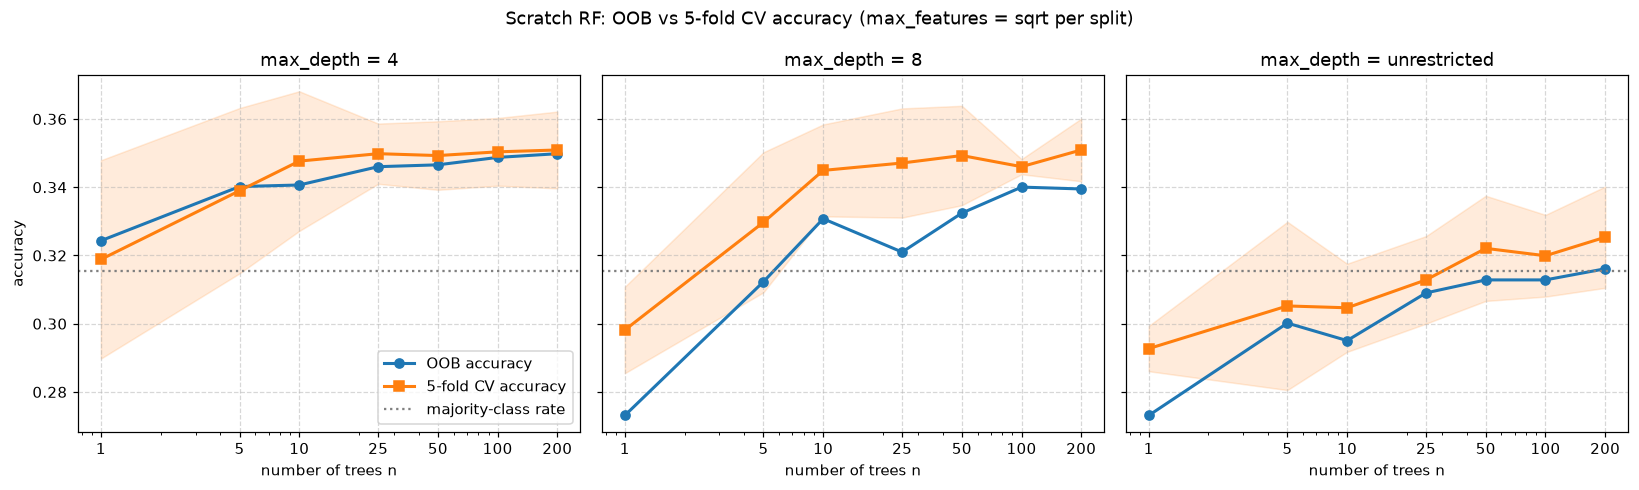

In [4]:
fig, axes = plt.subplots(1, len(DEPTHS), figsize=(15, 4.5), sharey=True)
for ax, depth in zip(axes, DEPTHS):
    d = sweep[sweep.max_depth == str(depth)]
    ax.plot(d.n, d.oob_acc, "o-", lw=2, label="OOB accuracy")
    ax.plot(d.n, d.cv_acc, "s-", lw=2, label="5-fold CV accuracy")
    ax.fill_between(d.n, d.cv_acc - d.cv_acc_std, d.cv_acc + d.cv_acc_std, alpha=0.15, color="C1")
    ax.axhline((y_train == "A").mean(), color="grey", ls=":", label="majority-class rate")
    ax.set_xscale("log"); ax.set_xticks(N_TREES_LIST)
    ax.xaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_title(f"max_depth = {depth if depth else 'unrestricted'}")
    ax.set_xlabel("number of trees n"); ax.grid(ls="--", alpha=.5)
axes[0].set_ylabel("accuracy"); axes[0].legend()
plt.suptitle("Scratch RF: OOB vs 5-fold CV accuracy (max_features = sqrt per split)")
plt.tight_layout(); plt.savefig("plots/rf_accuracy_vs_ntrees.png", dpi=150, bbox_inches="tight"); plt.show()

**Shape of the curves (numbers from the table above).**

* **Small n is noisy.** With one tree the CV accuracy is 0.319 (depth 4), 0.298 (depth 8) and 0.293 (unrestricted).
  Averaging more decorrelated trees lowers the variance of the vote, so accuracy rises quickly up to n ≈ 10–25 and then
  levels off. From n = 50 to n = 200 the CV accuracy changes by +0.0016 (depth 4: 0.3493 → 0.3509), +0.0016 (depth 8:
  0.3493 → 0.3509) and +0.0033 (unrestricted: 0.3221 → 0.3254). All of these are smaller than the fold-to-fold std
  (about 0.009–0.015). Extra trees do not cause overfitting; they just stop helping.
* **Depth matters more than n.** Shallow trees (depth 4) reach about 0.35 CV accuracy. Unrestricted trees reach only
  0.293–0.325, because each deep tree fits noise in its bootstrap sample and averaging only partly cancels it. The signal
  is weak: the majority-class rate is 580/1838 = 0.316 (dotted line).
* **Accuracy and macro-F1 move in opposite directions.** Depth-4 forests get their accuracy by predicting mostly the two
  largest segments (A and D), so their CV macro-F1 is only 0.213–0.236. Depth 8 gives 0.256–0.267. Unrestricted forests
  have lower accuracy but the best macro-F1 (0.282–0.311, highest at n = 200: 0.3109), because they also predict B and C.
* **OOB vs CV.** For the chosen configuration (unrestricted, n = 200) the OOB accuracy is 0.3161 and the 5-fold CV
  accuracy is 0.3254; at depth 4, n = 200 they are 0.3498 vs 0.3509. OOB sits slightly below CV because each row's OOB
  prediction is a vote of only ≈37% of the trees (each tree leaves out about 36.8% of the rows), a weaker forest than the
  full one, so OOB is slightly pessimistic, most visibly at small n. It is still an almost-free stand-in for cross-validation.

**Selected configuration.** Because the classes are imbalanced (and the task asks us to handle that), the RF is selected
by **5-fold CV macro-F1**, the same criterion used for the SVM grid searches; ties go to fewer trees. Accuracy is still
reported. The choice saved to `rf_best_params.json` is:

```python
n_estimators = 200
max_depth = None   # unrestricted
```

It has CV macro-F1 0.3109 (±0.0221) and CV accuracy 0.3254 (±0.0148); OOB accuracy on the full training set is 0.3161.
Selecting by accuracy would instead have picked a shallow forest (depth 4 or 8, n = 200, CV accuracy 0.3509) that almost
never predicts B or C (macro-F1 0.216–0.267).

In [5]:
# Final configuration: best mean CV macro-F1 in the sweep above (same criterion as the SVMs,
# because the classes are imbalanced); ties -> fewer trees. Accuracy is reported too.
best_row = sweep.sort_values(["cv_macro_f1", "n"], ascending=[False, True]).iloc[0]
BEST_DEPTH = None if best_row.max_depth == "None" else int(best_row.max_depth)
BEST_N = int(best_row.n)
RF_PARAMS = dict(n_estimators=BEST_N, max_depth=BEST_DEPTH, random_state=42)
with open("rf_best_params.json", "w") as f:
    json.dump(RF_PARAMS, f, indent=2)
print("Chosen RF params:", RF_PARAMS)
print(f"CV macro-F1 of chosen config: {best_row.cv_macro_f1:.4f} ± {best_row.cv_macro_f1_std:.4f}")
print(f"CV accuracy of chosen config: {best_row.cv_acc:.4f} ± {best_row.cv_acc_std:.4f}")

rf_final = make_rf_pipeline(**RF_PARAMS).fit(X_train, y_train)
print(f"OOB accuracy (full training set): {rf_final.named_steps['clf'].oob_score_:.4f}")

Chosen RF params: {'n_estimators': 200, 'max_depth': None, 'random_state': 42}
CV macro-F1 of chosen config: 0.3109 ± 0.0221
CV accuracy of chosen config: 0.3254 ± 0.0148
OOB accuracy (full training set): 0.3161


**Caveat (selection bias).** `max_depth` and `n` were chosen by macro-F1 on the *same* 5-fold CV that is reported below,
so the CV metrics of the chosen configuration are slightly optimistic (a nested CV would remove this bias). The OOB
estimate (accuracy 0.3161, macro-F1 0.3004) is a second, nearly independent check and is indeed a little lower.

=== 5-fold CV (out-of-fold) ===
Accuracy   : 0.3254
Macro-F1   : 0.3113
Weighted-F1: 0.3227
              precision    recall  f1-score   support

           A     0.3364    0.3759    0.3550       580
           B     0.2702    0.2481    0.2587       391
           C     0.2953    0.2344    0.2613       320
           D     0.3605    0.3803    0.3701       547

    accuracy                         0.3254      1838
   macro avg     0.3156    0.3096    0.3113      1838
weighted avg     0.3223    0.3254    0.3227      1838

=== OOB (final model) ===
Accuracy: 0.3161   Macro-F1: 0.3004
              precision    recall  f1-score   support

           A     0.3338    0.3793    0.3551       580
           B     0.2535    0.2302    0.2413       391
           C     0.2773    0.2219    0.2465       320
           D     0.3521    0.3656    0.3587       547

    accuracy                         0.3161      1838
   macro avg     0.3042    0.2992    0.3004      1838
weighted avg     0.3124    0.31

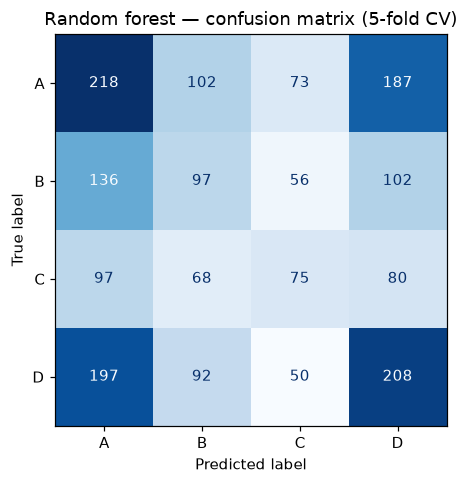

In [6]:
# Task 2c: accuracy, per-class P/R/F1 and macro-F1 from 5-fold CV (out-of-fold) predictions and from OOB
cv_pred = np.empty(len(y_train), dtype=object)
for tr, va in folds:
    m = make_rf_pipeline(**RF_PARAMS).fit(X_train.iloc[tr], y_train[tr])
    cv_pred[va] = m.predict(X_train.iloc[va])
cv_pred = cv_pred.astype(str)
print("=== 5-fold CV (out-of-fold) ===")
print(f"Accuracy   : {accuracy_score(y_train, cv_pred):.4f}")
print(f"Macro-F1   : {f1_score(y_train, cv_pred, average='macro'):.4f}")
print(f"Weighted-F1: {f1_score(y_train, cv_pred, average='weighted'):.4f}")
print(classification_report(y_train, cv_pred, digits=4, zero_division=0))

clf = rf_final.named_steps["clf"]
yo = y_train[clf.oob_mask_]
print("=== OOB (final model) ===")
print(f"Accuracy: {accuracy_score(yo, clf.oob_pred_):.4f}   Macro-F1: {f1_score(yo, clf.oob_pred_, average='macro'):.4f}")
print(classification_report(yo, clf.oob_pred_, digits=4, zero_division=0))

cm = confusion_matrix(y_train, cv_pred, labels=classes)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Random forest — confusion matrix (5-fold CV)")
plt.tight_layout(); plt.savefig("plots/cm_rf.png", dpi=150, bbox_inches="tight"); plt.show()

In [7]:
# Task 2c: test predictions -> rf.csv (all rows printed)
test_pred = rf_final.predict(X_test)
pd.DataFrame({"predicted": test_pred}).to_csv("rf.csv", index=False)
pd.set_option("display.max_rows", None)
print(pd.DataFrame({"row": np.arange(len(test_pred)), "predicted": test_pred}).to_string(index=False))
print("\nPredicted distribution:", pd.Series(test_pred).value_counts().to_dict())
print(f"Saved rf.csv ({len(test_pred)} rows)")

 row predicted
   0         D
   1         A
   2         B
   3         D
   4         A
   5         A
   6         C
   7         A
   8         A
   9         B
  10         B
  11         C
  12         D
  13         A
  14         D
  15         A
  16         C
  17         A
  18         D
  19         B
  20         B
  21         D
  22         B
  23         A
  24         D
  25         C
  26         A
  27         C
  28         B
  29         A
  30         A
  31         A
  32         D
  33         C
  34         D
  35         C
  36         D
  37         A
  38         A
  39         A
  40         A
  41         A
  42         B
  43         D
  44         D
  45         B
  46         D
  47         A
  48         D
  49         A
  50         A
  51         B
  52         D
  53         A
  54         B
  55         A
  56         C
  57         B
  58         C
  59         B
  60         B
  61         A
  62         D
  63         B
  64         C
  65      

Held-out accuracy 0.3087, macro-F1 0.2966
      attribute  acc_drop_mean  acc_drop_std  macroF1_drop_mean  macroF1_drop_std
            Age         0.0270        0.0184             0.0402            0.0194
    Family_Size         0.0159        0.0125             0.0180            0.0129
         Gender         0.0114        0.0149             0.0233            0.0153
   Ever_Married         0.0055        0.0110             0.0066            0.0107
     Profession         0.0030        0.0146             0.0145            0.0150
 Spending_Score         0.0029        0.0103             0.0041            0.0110
          Var_1        -0.0036        0.0100             0.0045            0.0108
      Graduated        -0.0075        0.0111            -0.0020            0.0111
Work_Experience        -0.0081        0.0129            -0.0030            0.0124


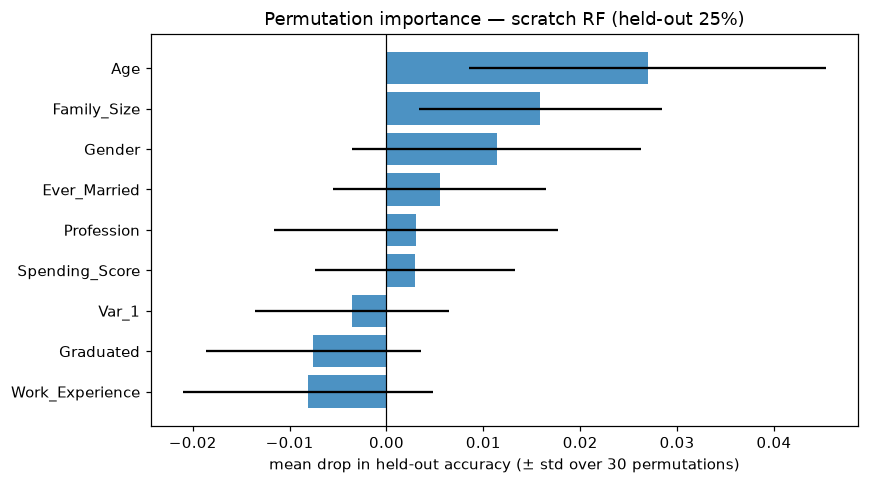

In [8]:
# Task 2d: permutation importance on held-out data (25% stratified hold-out, 30 repeats)
X_fit, X_hold, y_fit, y_hold = train_test_split(X_train, y_train, test_size=0.25,
                                                stratify=y_train, random_state=42)
rf_hold = make_rf_pipeline(**RF_PARAMS).fit(X_fit, y_fit)
hp = rf_hold.predict(X_hold)
print(f"Held-out accuracy {accuracy_score(y_hold, hp):.4f}, macro-F1 {f1_score(y_hold, hp, average='macro'):.4f}")
# permutes the RAW input columns, so each one-hot group is permuted as one attribute
pi = permutation_importance(rf_hold, X_hold, y_hold, n_repeats=30, random_state=0,
                            scoring=["accuracy", "f1_macro"], n_jobs=-1)
imp = pd.DataFrame({"attribute": X_hold.columns,
                    "acc_drop_mean": pi["accuracy"].importances_mean,
                    "acc_drop_std": pi["accuracy"].importances_std,
                    "macroF1_drop_mean": pi["f1_macro"].importances_mean,
                    "macroF1_drop_std": pi["f1_macro"].importances_std}
                   ).sort_values("acc_drop_mean", ascending=False, ignore_index=True)
print(imp.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
d = imp.iloc[::-1]
ax.barh(d.attribute, d.acc_drop_mean, xerr=d.acc_drop_std, color="C0", alpha=.8)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("mean drop in held-out accuracy (± std over 30 permutations)")
ax.set_title("Permutation importance — scratch RF (held-out 25%)")
plt.tight_layout(); plt.savefig("plots/rf_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation (from the table above; 25% stratified hold-out, 30 permutations per attribute).**
The model fitted on the other 75% scores 0.3087 accuracy and 0.2966 macro-F1 on the hold-out. The "± std" is the spread
over the 30 shuffles of one hold-out set (459 rows), so it understates the true sampling uncertainty.

* **Age** has the largest effect: shuffling it lowers accuracy by 0.0270 ± 0.0184 and macro-F1 by 0.0402 ± 0.0194
  (about 1.5 and 2 std above zero).
* **Family_Size** (accuracy drop 0.0159 ± 0.0125, 1.27 std; macro-F1 0.0180 ± 0.0129): with Age, the only attribute whose
  ±1 std interval excludes zero. **Gender** (0.0114 ± 0.0149, macro-F1 0.0233 ± 0.0153) comes next, within 1 std of zero.
* **Ever_Married** (0.0055 ± 0.0110), **Profession** (0.0030 ± 0.0146; macro-F1 0.0145 ± 0.0150) and
  **Spending_Score** (0.0029 ± 0.0103) have positive mean drops that are well inside the noise.
* **Var_1** (−0.0036), **Graduated** (−0.0075) and **Work_Experience** (−0.0081) have *negative* mean accuracy drops:
  shuffling them does not hurt (and slightly helps) this model, so it gets no usable signal from them.

So six of nine attributes have a positive mean accuracy drop, but only Age and Family_Size are clearly above zero, and the rank order below the top two or three would likely change with another split.

**Business sense.** That age and household size matter most is plausible: life stage drives what kind of car a customer
buys and how a sales team would group them. A gender effect is possible but weak here and should not drive targeting.
It is less intuitive that Spending_Score, Profession and Work_Experience add almost nothing, which suggests the sales
team's segments were not defined mainly by these fields (or the information overlaps with Age). The effects are small in
absolute terms: even Age is worth under 3 points of accuracy. **The attributes in this file explain little of the
segmentation**, so the ranking is suggestive, not evidence of strong drivers.

Note on the model: the selected configuration (`n_estimators = 200`, `max_depth = None`, chosen by CV macro-F1) has 5-fold
out-of-fold accuracy 0.3254 and macro-F1 0.3113. It predicts all four classes with fairly even recall (0.376 for A,
0.248 for B, 0.234 for C and 0.380 for D). Task 3 (`teamId_task3_analysis.ipynb`) compares it with the class-balanced SVMs.